In [44]:
import warnings
warnings.filterwarnings('ignore')

# Import Neccessary libraries
import numpy as np 
import pandas as pd 

# Import Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

#Import Model
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.pipeline import Pipeline

#Import Sampler libraries
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as imbPipeline

# Set the decimal format
pd.options.display.float_format = "{:.2f}".format

In [45]:
import sqlite3
import pandas as pd

# Connect to the SQLite data warehouse
conn = sqlite3.connect("diabetes_dw.sqlite")

# 1. Check row counts again
counts = pd.read_sql_query("""
    SELECT
      (SELECT COUNT(*) FROM stgDiabetes)          AS StagingCount,
      (SELECT COUNT(*) FROM DimPatient)            AS DimCount,
      (SELECT COUNT(*) FROM FactDiabetesMeasures)  AS FactCount
""", conn)
print(counts)

# 2. Preview a few joined rows to confirm referential integrity
preview = pd.read_sql_query("""
    SELECT
      f.FactKey,
      d.PatientKey, d.Gender, d.Age, d.BMI, d.HypertensionFlag, d.HeartDiseaseFlag, d.SmokingHistory,
      f.HbA1cLevel, f.BloodGlucoseLevel, f.DiabetesFlag
    FROM FactDiabetesMeasures AS f
    JOIN DimPatient AS d ON f.PatientKey = d.PatientKey
    LIMIT 5;
""", conn)
print(preview)

conn.close()

   StagingCount  DimCount  FactCount
0        100000     68514     100000
   FactKey  PatientKey  Gender  Age   BMI  HypertensionFlag  HeartDiseaseFlag  \
0        1           1  Female   80 25.19                 0                 1   
1        2           2  Female   54 27.32                 0                 0   
2        3           3    Male   28 27.32                 0                 0   
3        4           4  Female   36 23.45                 0                 0   
4        5           5    Male   76 20.14                 1                 1   

  SmokingHistory  HbA1cLevel  BloodGlucoseLevel  DiabetesFlag  
0     non-smoker        6.60                140             0  
1     non-smoker        6.60                 80             0  
2     non-smoker        5.70                158             0  
3        current        5.00                155             0  
4        current        4.80                155             0  


### <b>III <span style='color:#16C2D5'>|</span> Input the data</b> 

In [46]:
import sqlite3
import pandas as pd

conn = sqlite3.connect("diabetes_dw.sqlite")
df = pd.read_sql_query("SELECT * FROM stgDiabetes;", conn)
conn.close()

print("Loaded DataFrame shape:", df.shape)
df.head()

Loaded DataFrame shape: (100000, 9)


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.00,0,1,non-smoker,25.19,6.60,140,0
1,Female,54.00,0,0,non-smoker,27.32,6.60,80,0
2,Male,28.00,0,0,non-smoker,27.32,5.70,158,0
3,Female,36.00,0,0,current,23.45,5.00,155,0
4,Male,76.00,1,1,current,20.14,4.80,155,0


In [47]:
print(df['smoking_history'].unique())
print(df['smoking_history'].value_counts())

['non-smoker' 'current' 'past_smoker']
smoking_history
non-smoker     70911
past_smoker    19803
current         9286
Name: count, dtype: int64


<b><span style='color:white'>1 | EXPLORATORY DATA ANALYSIS </span></b> </div>

<b><span style='color:white'> 1. Data Quality</span></b> </div>

### <b>I <span style='color:#16C2D5'>|</span> Handling Duplicates</b> 

In [50]:
duplicate_rows_data = df[df.duplicated()]
print("number of duplicate rows:", duplicate_rows_data.shape)
df = df.drop_duplicates()

number of duplicate rows: (0, 9)


In [51]:
df = df.drop_duplicates()

In [52]:
# Example DSS Query 1: Percentage of diabetics by age group
conn = sqlite3.connect("diabetes_dw.sqlite")
age_group_pct = pd.read_sql_query("""
    SELECT
      CASE
        WHEN Age < 30 THEN 'Under 30'
        WHEN Age BETWEEN 30 AND 50 THEN '30-50'
        WHEN Age BETWEEN 51 AND 70 THEN '51-70'
        ELSE '71+'
      END AS AgeGroup,
      ROUND(AVG(DiabetesFlag)*100.0, 2) AS PctDiabetic
    FROM FactDiabetesMeasures f
    JOIN DimPatient d ON f.PatientKey = d.PatientKey
    GROUP BY AgeGroup;
""", conn)
print(age_group_pct)
conn.close()

   AgeGroup  PctDiabetic
0     30-50         5.42
1     51-70        15.93
2       71+        20.15
3  Under 30         0.84


   Gender  PctDiabetic
0  Female         7.62
1    Male         9.75
2   Other         0.00


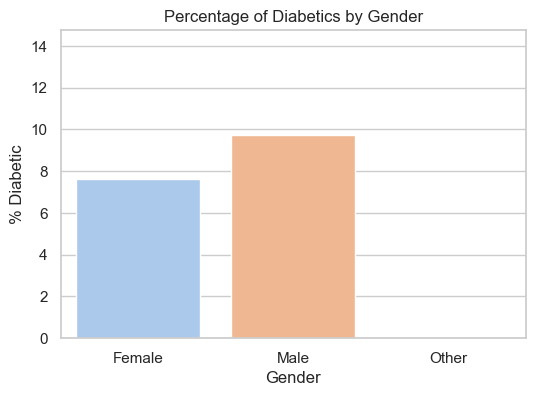

In [53]:
conn = sqlite3.connect("diabetes_dw.sqlite")

# Query: percentage of diabetics by gender
gender_pct = pd.read_sql_query("""
    SELECT
      d.Gender,
      ROUND(AVG(f.DiabetesFlag)*100.0, 2) AS PctDiabetic
    FROM FactDiabetesMeasures f
    JOIN DimPatient d ON f.PatientKey = d.PatientKey
    GROUP BY d.Gender;
""", conn)

conn.close()

# Display the DataFrame
print(gender_pct)

# Plotting
sns.set_theme(style="whitegrid")
plt.figure(figsize=(6,4))
sns.barplot(data=gender_pct, x="Gender", y="PctDiabetic", palette="pastel")
plt.title("Percentage of Diabetics by Gender")
plt.ylabel("% Diabetic")
plt.ylim(0, gender_pct["PctDiabetic"].max() + 5)
plt.show()


  SmokingHistory            Status  Count
0        current     DiabeticCount    948
1     non-smoker     DiabeticCount   4800
2    past_smoker     DiabeticCount   2752
3        current  NonDiabeticCount   8338
4     non-smoker  NonDiabeticCount  66111
5    past_smoker  NonDiabeticCount  17051


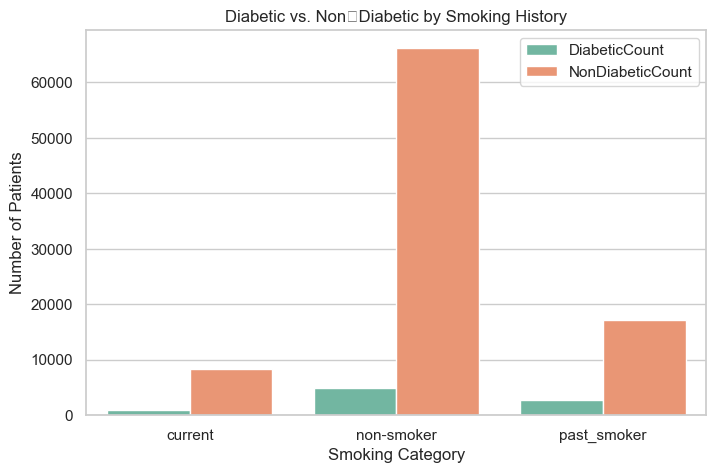

In [54]:
conn = sqlite3.connect("diabetes_dw.sqlite")

# Query: diabetic vs non‐diabetic counts by smoking category
smoke_counts = pd.read_sql_query("""
    SELECT
      d.SmokingHistory,
      SUM(f.DiabetesFlag) AS DiabeticCount,
      COUNT(*) - SUM(f.DiabetesFlag) AS NonDiabeticCount
    FROM FactDiabetesMeasures f
    JOIN DimPatient d ON f.PatientKey = d.PatientKey
    GROUP BY d.SmokingHistory;
""", conn)

conn.close()

# Melt for easier plotting
smoke_melted = smoke_counts.melt(
    id_vars="SmokingHistory",
    value_vars=["DiabeticCount", "NonDiabeticCount"],
    var_name="Status", value_name="Count"
)

print(smoke_melted)

# Plotting
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8,5))
sns.barplot(data=smoke_melted, x="SmokingHistory", y="Count", hue="Status", palette="Set2")
plt.title("Diabetic vs. Non‐Diabetic by Smoking History")
plt.ylabel("Number of Patients")
plt.xlabel("Smoking Category")
plt.legend(title="")
plt.show()


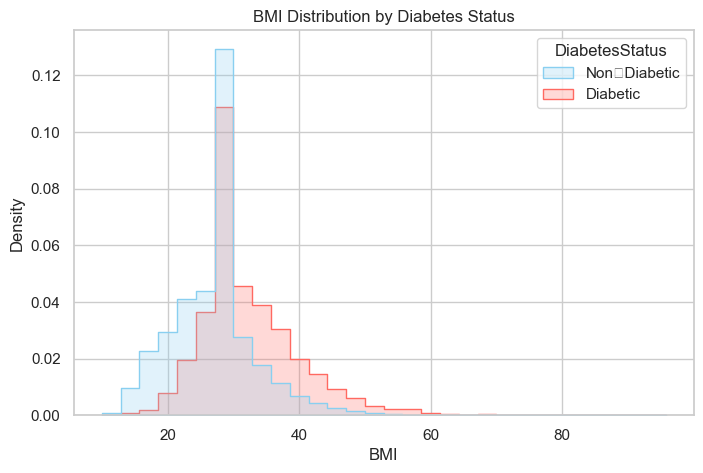

In [55]:
conn = sqlite3.connect("diabetes_dw.sqlite")

# Query: get BMI and DiabetesFlag for all patients
bmi_df = pd.read_sql_query("""
    SELECT
      d.BMI,
      f.DiabetesFlag
    FROM FactDiabetesMeasures f
    JOIN DimPatient d ON f.PatientKey = d.PatientKey;
""", conn)

conn.close()

# Map 0/1 to labels
bmi_df["DiabetesStatus"] = bmi_df["DiabetesFlag"].map({0: "Non‐Diabetic", 1: "Diabetic"})

# Plotting
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8,5))
sns.histplot(
    data=bmi_df,
    x="BMI",
    hue="DiabetesStatus",
    bins=30,
    element="step",
    stat="density",
    common_norm=False,
    palette=["#89CFF0", "#FF6961"]
)
plt.title("BMI Distribution by Diabetes Status")
plt.xlabel("BMI")
plt.ylabel("Density")
plt.show()


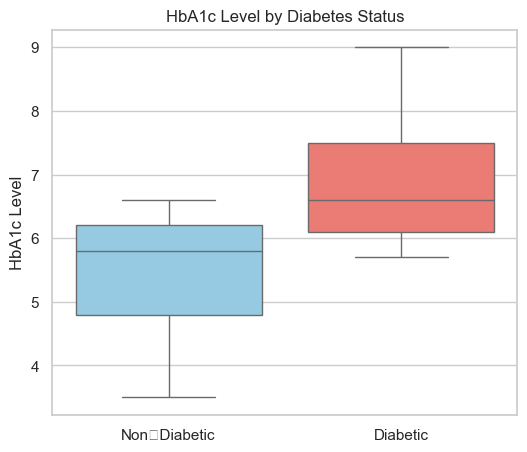

In [56]:
conn = sqlite3.connect("diabetes_dw.sqlite")

# Query: HbA1c levels and diabetes flag
hba1c_df = pd.read_sql_query("""
    SELECT
      f.HbA1cLevel AS HbA1c,
      f.DiabetesFlag
    FROM FactDiabetesMeasures f
    JOIN DimPatient d ON f.PatientKey = d.PatientKey;
""", conn)

conn.close()

# Map 0/1 to labels
hba1c_df["DiabetesStatus"] = hba1c_df["DiabetesFlag"].map({0: "Non‐Diabetic", 1: "Diabetic"})

# Plotting
sns.set_theme(style="whitegrid")
plt.figure(figsize=(6,5))
sns.boxplot(data=hba1c_df, x="DiabetesStatus", y="HbA1c", palette=["#89CFF0", "#FF6961"])
plt.title("HbA1c Level by Diabetes Status")
plt.xlabel("")
plt.ylabel("HbA1c Level")
plt.show()


  SmokingHistory  AvgGlucose
0        current      139.64
1     non-smoker      136.98
2    past_smoker      141.18


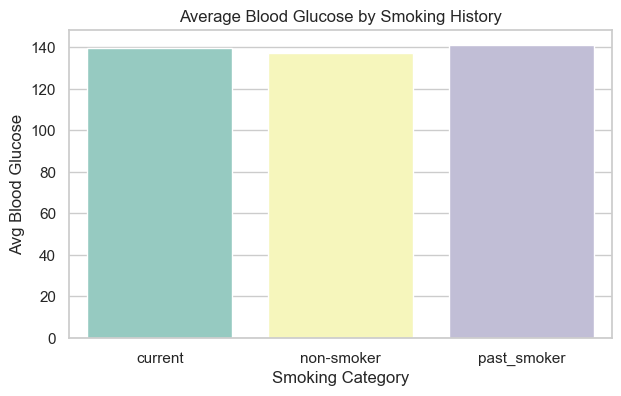

In [57]:
import sqlite3
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

conn = sqlite3.connect("diabetes_dw.sqlite")

# Query: average blood glucose by smoking category
glucose_avg = pd.read_sql_query("""
    SELECT
      d.SmokingHistory,
      ROUND(AVG(f.BloodGlucoseLevel), 2) AS AvgGlucose
    FROM FactDiabetesMeasures f
    JOIN DimPatient d ON f.PatientKey = d.PatientKey
    GROUP BY d.SmokingHistory;
""", conn)

conn.close()

print(glucose_avg)

# Plotting
sns.set_theme(style="whitegrid")
plt.figure(figsize=(7,4))
sns.barplot(data=glucose_avg, x="SmokingHistory", y="AvgGlucose", palette="Set3")
plt.title("Average Blood Glucose by Smoking History")
plt.xlabel("Smoking Category")
plt.ylabel("Avg Blood Glucose")
plt.show()

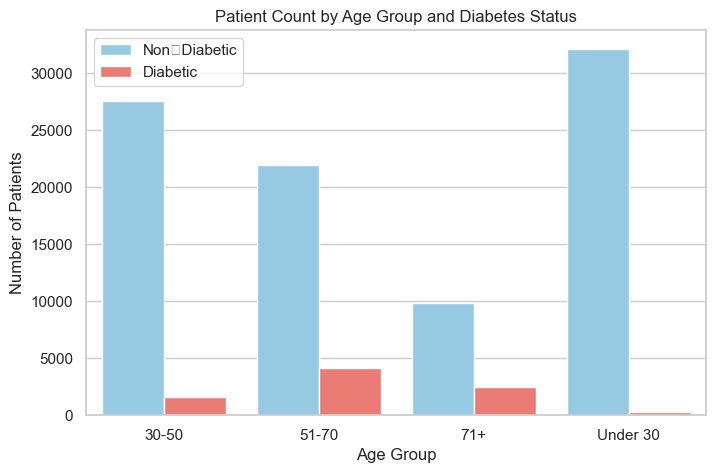

In [58]:
conn = sqlite3.connect("diabetes_dw.sqlite")

# Query: count by age group and status
age_group_counts = pd.read_sql_query("""
    SELECT
      CASE
        WHEN d.Age < 30 THEN 'Under 30'
        WHEN d.Age BETWEEN 30 AND 50 THEN '30-50'
        WHEN d.Age BETWEEN 51 AND 70 THEN '51-70'
        ELSE '71+'
      END AS AgeGroup,
      f.DiabetesFlag,
      COUNT(*) AS Count
    FROM FactDiabetesMeasures f
    JOIN DimPatient d ON f.PatientKey = d.PatientKey
    GROUP BY AgeGroup, f.DiabetesFlag;
""", conn)

conn.close()

# Map 0/1 to labels
age_group_counts["DiabetesStatus"] = age_group_counts["DiabetesFlag"].map({0: "Non‐Diabetic", 1: "Diabetic"})

# Plotting
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8,5))
sns.barplot(
    data=age_group_counts,
    x="AgeGroup",
    y="Count",
    hue="DiabetesStatus",
    palette=["#89CFF0", "#FF6961"]
)
plt.title("Patient Count by Age Group and Diabetes Status")
plt.xlabel("Age Group")
plt.ylabel("Number of Patients")
plt.legend(title="")
plt.show()


### <b>II <span style='color:#16C2D5'>|</span> Uniqueness</b> 

In [59]:
# Loop through each column and count the number of distinct values
for column in df.columns:
    num_distinct_values = len(df[column].unique())
    print(f"{column}: {num_distinct_values} distinct values")

gender: 3 distinct values
age: 102 distinct values
hypertension: 2 distinct values
heart_disease: 2 distinct values
smoking_history: 3 distinct values
bmi: 4247 distinct values
HbA1c_level: 18 distinct values
blood_glucose_level: 18 distinct values
diabetes: 2 distinct values


### <b>III <span style='color:#16C2D5'>|</span> Missing Values</b> 

In [60]:
# Checking null values
print(df.isnull().sum())

gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64


In [61]:
# Remove Unneccessary value [0.00195%]
df = df[df['gender'] != 'Other']

### <b>IV <span style='color:#16C2D5'>|</span> Describe the Data</b> 

In [62]:
df.describe().style.format("{:.2f}")

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
count,93971.00,93971.00,93971.00,93971.00,93971.00,93971.00,93971.00
mean,41.76,0.08,0.04,27.32,5.54,138.30,0.09
std,22.50,0.27,0.20,6.84,1.07,41.02,0.29
min,0.08,0.00,0.00,10.01,3.50,80.00,0.00
25%,24.00,0.00,0.00,23.26,4.80,100.00,0.00
50%,43.00,0.00,0.00,27.32,5.80,140.00,0.00
75%,59.00,0.00,0.00,30.00,6.20,159.00,0.00
max,80.00,1.00,1.00,95.69,9.00,300.00,1.00


<b><span style='color:white'> 2. Univariate Analysis</span></b> </div>

### <b>I <span style='color:#16C2D5'>|</span> Histogram for age</b> 

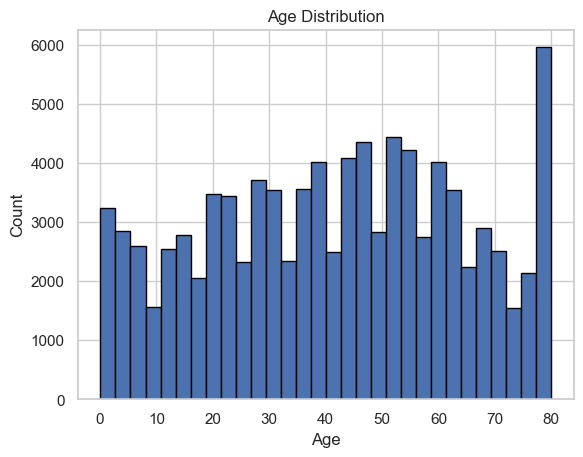

In [63]:
# Histogram for age
plt.hist(df['age'], bins=30, edgecolor='black')
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

### <b>II <span style='color:#16C2D5'>|</span> Bar plot for gender</b> 

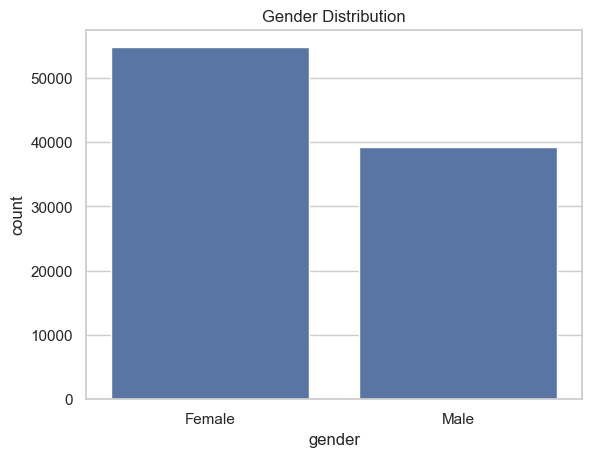

In [64]:
# Bar plot for gender
sns.countplot(x='gender', data=df)
plt.title('Gender Distribution')
plt.show()

### <b>III <span style='color:#16C2D5'> | </span> Distribution plot for BMI</b> 

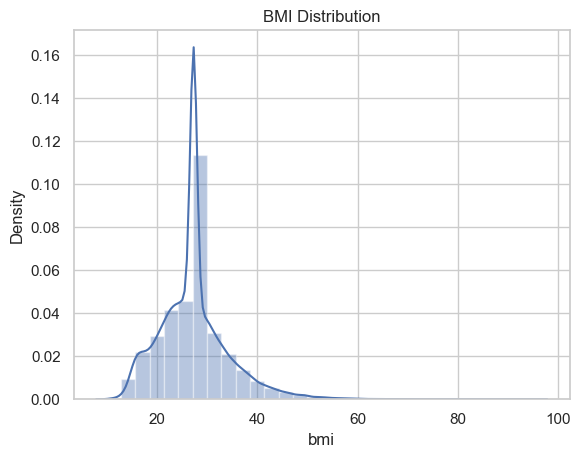

In [65]:
# Distribution plot for BMI
sns.distplot(df['bmi'], bins=30)
plt.title('BMI Distribution')
plt.show()

### <b>IV <span style='color:#16C2D5'>|</span> Count plots for binary variables</b> 

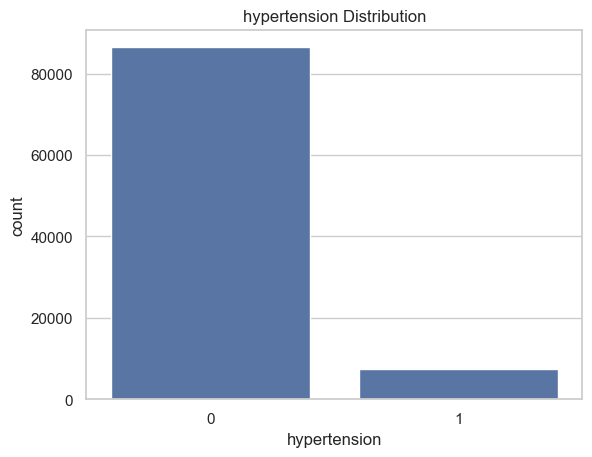

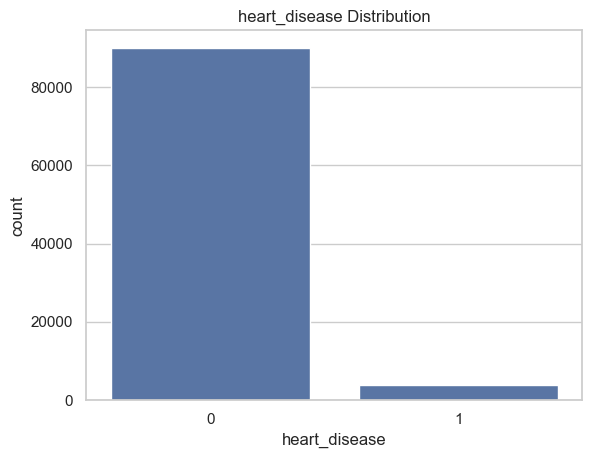

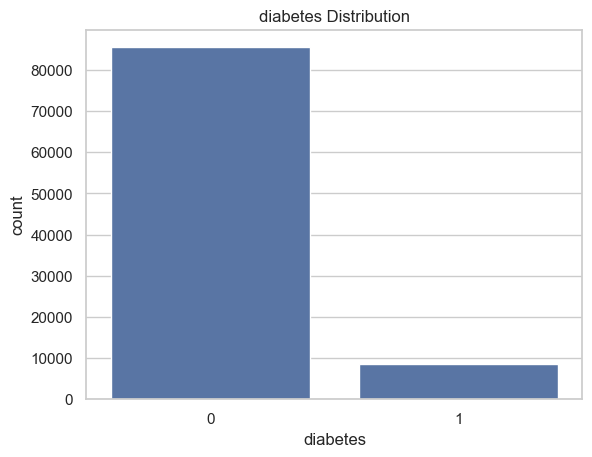

In [66]:
# Count plots for binary variables
for col in ['hypertension', 'heart_disease', 'diabetes']:
    sns.countplot(x=col, data=df)
    plt.title(f'{col} Distribution')
    plt.show()

### <b>V <span style='color:#16C2D5'>|</span> Count plot for smoking history</b> 

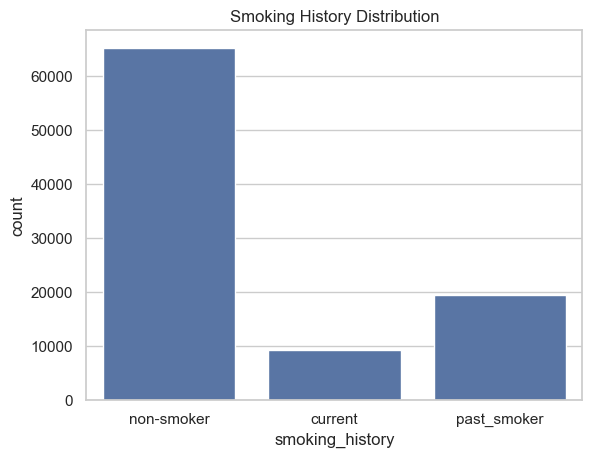

In [67]:
# Count plot for smoking history
sns.countplot(x='smoking_history', data=df)
plt.title('Smoking History Distribution')
plt.show()

<b><span style='color:white'> 3.Bivariative Analysis</span></b> </div>
### <b>I <span style='color:#16C2D5'>|</span> Boxplot BMI vs Diabetes classification</b> 

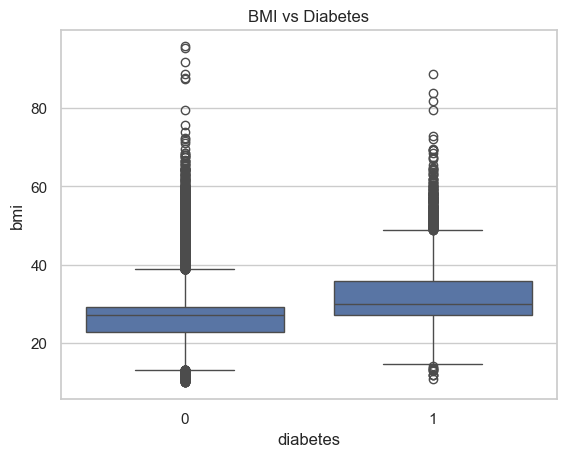

In [68]:
# Boxplot BMI vs Diabetes classification
sns.boxplot(x='diabetes', y='bmi', data=df)
plt.title('BMI vs Diabetes')
plt.show()

### <b>II <span style='color:#16C2D5'>|</span> Boxplot Age vs Diabetes classification</b> 

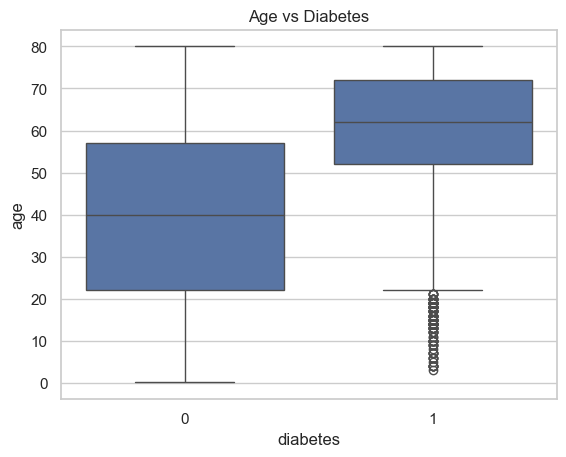

In [69]:
# Boxplot Age vs Diabetes classification
sns.boxplot(x='diabetes', y='age', data=df)
plt.title('Age vs Diabetes')
plt.show()

### <b>III <span style='color:#16C2D5'>|</span> Count plot of gender vs diabetes</b> 

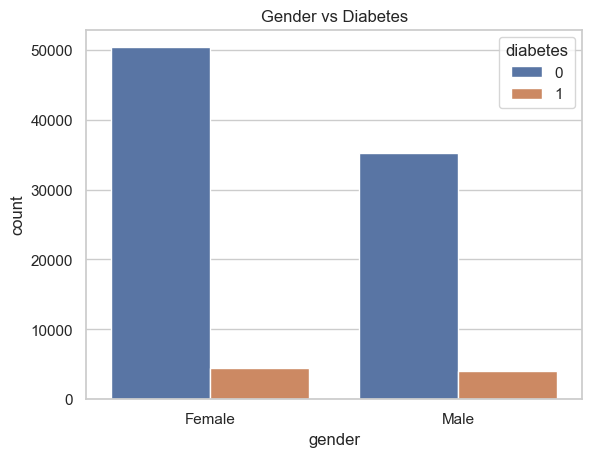

In [70]:
# Count plot of gender vs diabetes
sns.countplot(x='gender', hue='diabetes', data=df)
plt.title('Gender vs Diabetes')
plt.show()

### <b>III <span style='color:#16C2D5'>|</span> Boxplot HbA1c level vs Diabetes classification</b> 

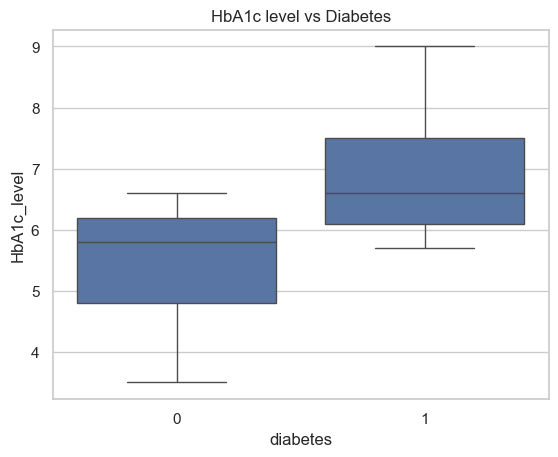

In [71]:
# Boxplot HbA1c level vs Diabetes classification
sns.boxplot(x='diabetes', y='HbA1c_level', data=df)
plt.title('HbA1c level vs Diabetes')
plt.show()

### <b>IV <span style='color:#16C2D5'>|</span> Boxplot blood glucose level vs Diabetes classification</b> 

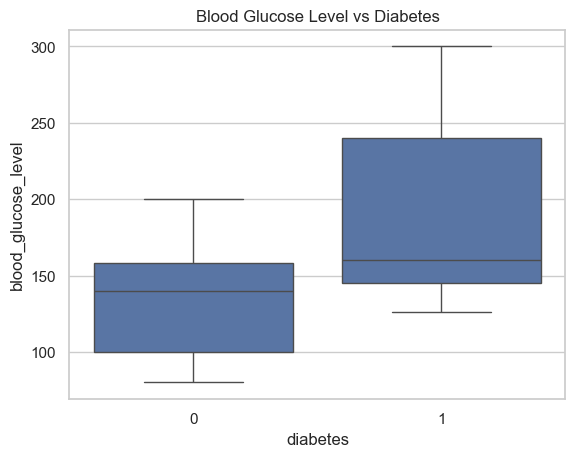

In [72]:
# Boxplot blood glucose level vs Diabetes classification
sns.boxplot(x='diabetes', y='blood_glucose_level', data=df)
plt.title('Blood Glucose Level vs Diabetes')
plt.show()

### <b>V <span style='color:#16C2D5'>|</span> Pair plot for numeric features</b> 

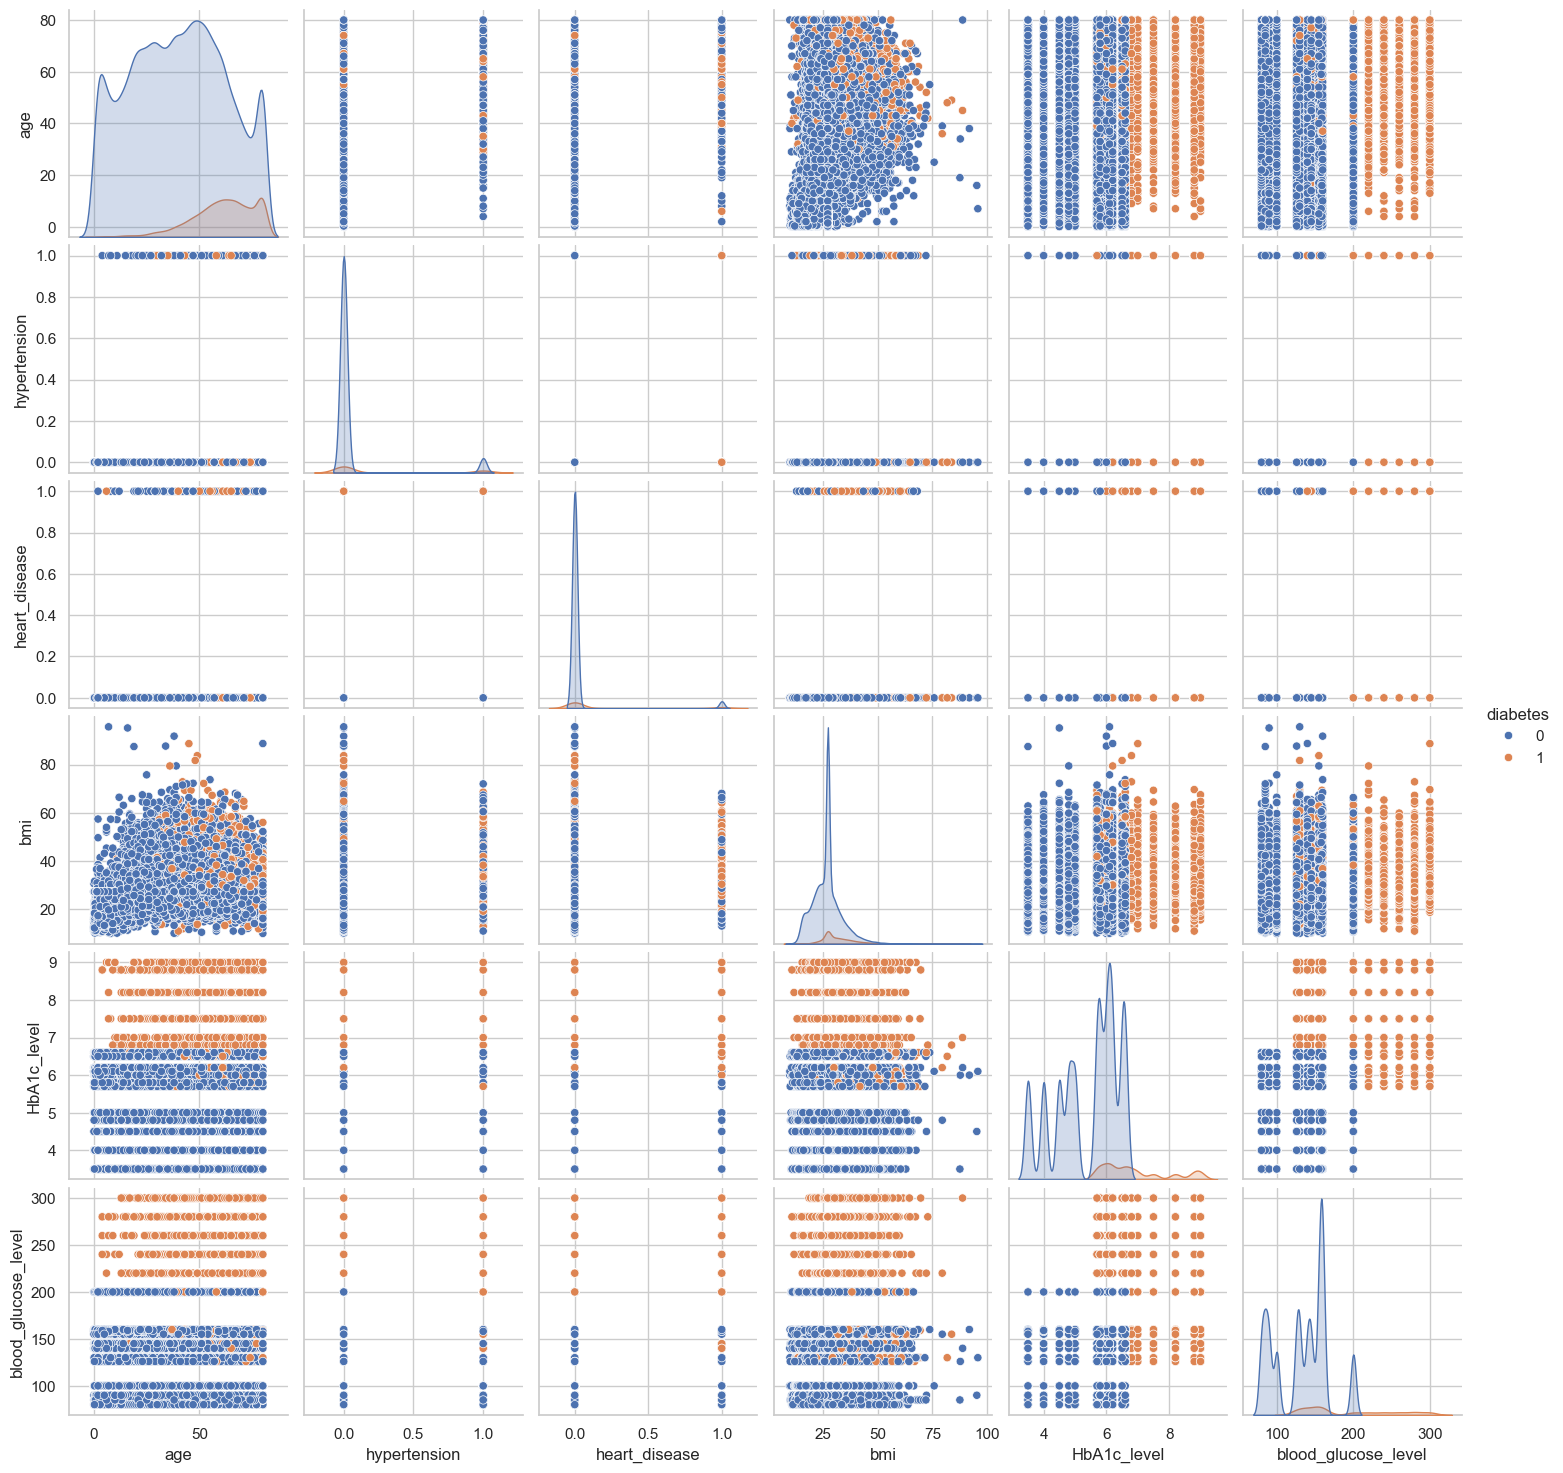

In [73]:
# Pair plot for numeric features
sns.pairplot(df, hue='diabetes')
plt.show()

<b><span style='color:white'> 4. Multivariate analysis</span></b> </div>

### <b>I <span style='color:#16C2D5'>|</span> Scatterplot Age vs BMI colored by Diabetes classification</b> 

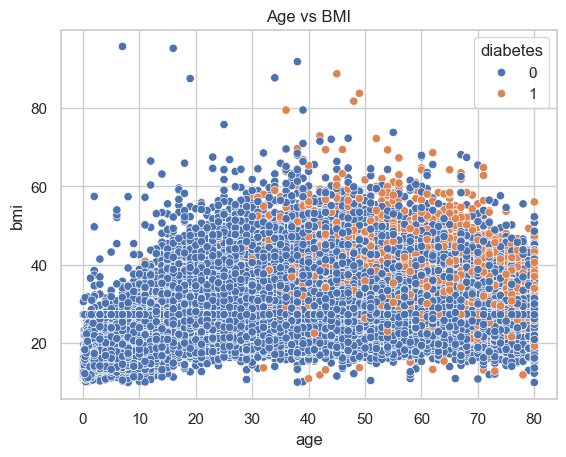

In [74]:
# Scatterplot Age vs BMI colored by Diabetes classification
sns.scatterplot(x='age', y='bmi', hue='diabetes', data=df)
plt.title('Age vs BMI')
plt.show()

### <b>II <span style='color:#16C2D5'>|</span> Violin plot of BMI against diabetes classification split by gender</b> 

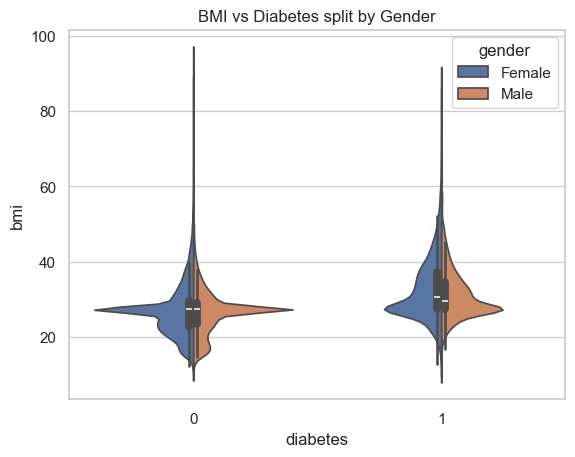

In [75]:
# Violin plot of BMI against diabetes classification split by gender
sns.violinplot(x='diabetes', y='bmi', hue='gender', split=True, data=df)
plt.title('BMI vs Diabetes split by Gender')
plt.show()

### <b>III <span style='color:#16C2D5'>|</span> Interaction between gender, BMI and diabetes</b> 

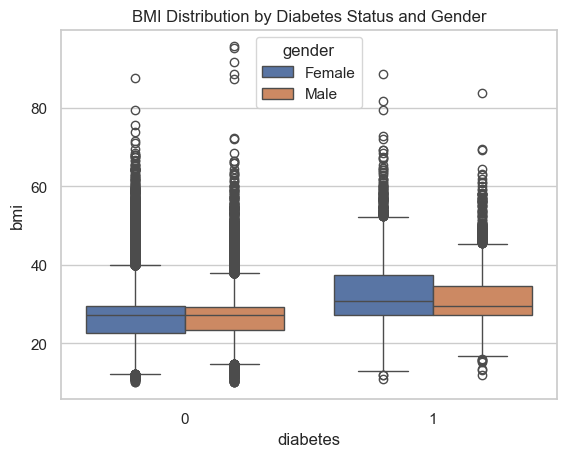

In [76]:
# Interaction between gender, BMI and diabetes
sns.boxplot(x='diabetes', y='bmi', hue='gender', data=df)
plt.title('BMI Distribution by Diabetes Status and Gender')
plt.show()

### <b>IV <span style='color:#16C2D5'>|</span> Interaction between gender, Age and diabetes</b> 

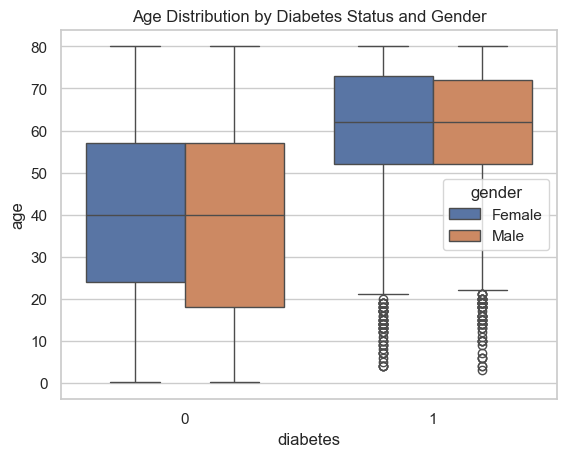

In [77]:
# Interaction between gender, Age and diabetes
sns.boxplot(x='diabetes', y='age', hue='gender', data=df)
plt.title('Age Distribution by Diabetes Status and Gender')
plt.show()

<b><span style='color:white'>2 | CORRELATION </span></b> </div>

### <b>I <span style='color:#16C2D5'>|</span> Data preparation</b> 

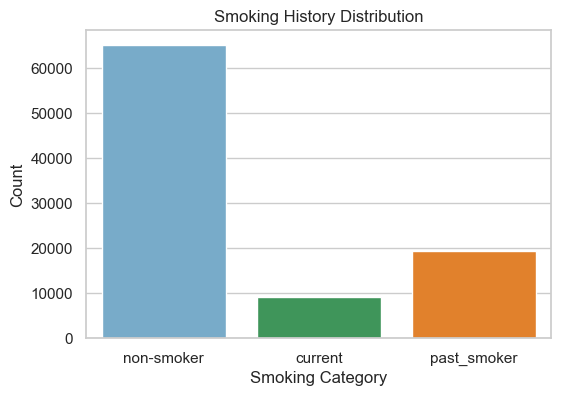

In [78]:
import seaborn as sns
import matplotlib.pyplot as plt

# Countplot of the three categories in smoking_history
sns.set_theme(style="whitegrid")
plt.figure(figsize=(6, 4))
sns.countplot(
    x="smoking_history",
    data=df,
    order=["non-smoker", "current", "past_smoker"],
    palette=["#6BAED6", "#31A354", "#FF7F0E"]
)
plt.title("Smoking History Distribution")
plt.xlabel("Smoking Category")
plt.ylabel("Count")
plt.show()

In [80]:
data = df.copy()

### <b>II <span style='color:#16C2D5'>|</span> Encoding</b> 

In [81]:
def perform_one_hot_encoding(df, column_name):
    # Perform one-hot encoding on the specified column
    dummies = pd.get_dummies(df[column_name], prefix=column_name)

    # Drop the original column and append the new dummy columns to the dataframe
    df = pd.concat([df.drop(column_name, axis=1), dummies], axis=1)

    return df

# Perform one-hot encoding on the gender variable
data = perform_one_hot_encoding(data, 'gender')

# Perform one-hot encoding on the smoking history variable
data = perform_one_hot_encoding(data, 'smoking_history')

### <b>III <span style='color:#16C2D5'>|</span> Correlation Matrix</b> 

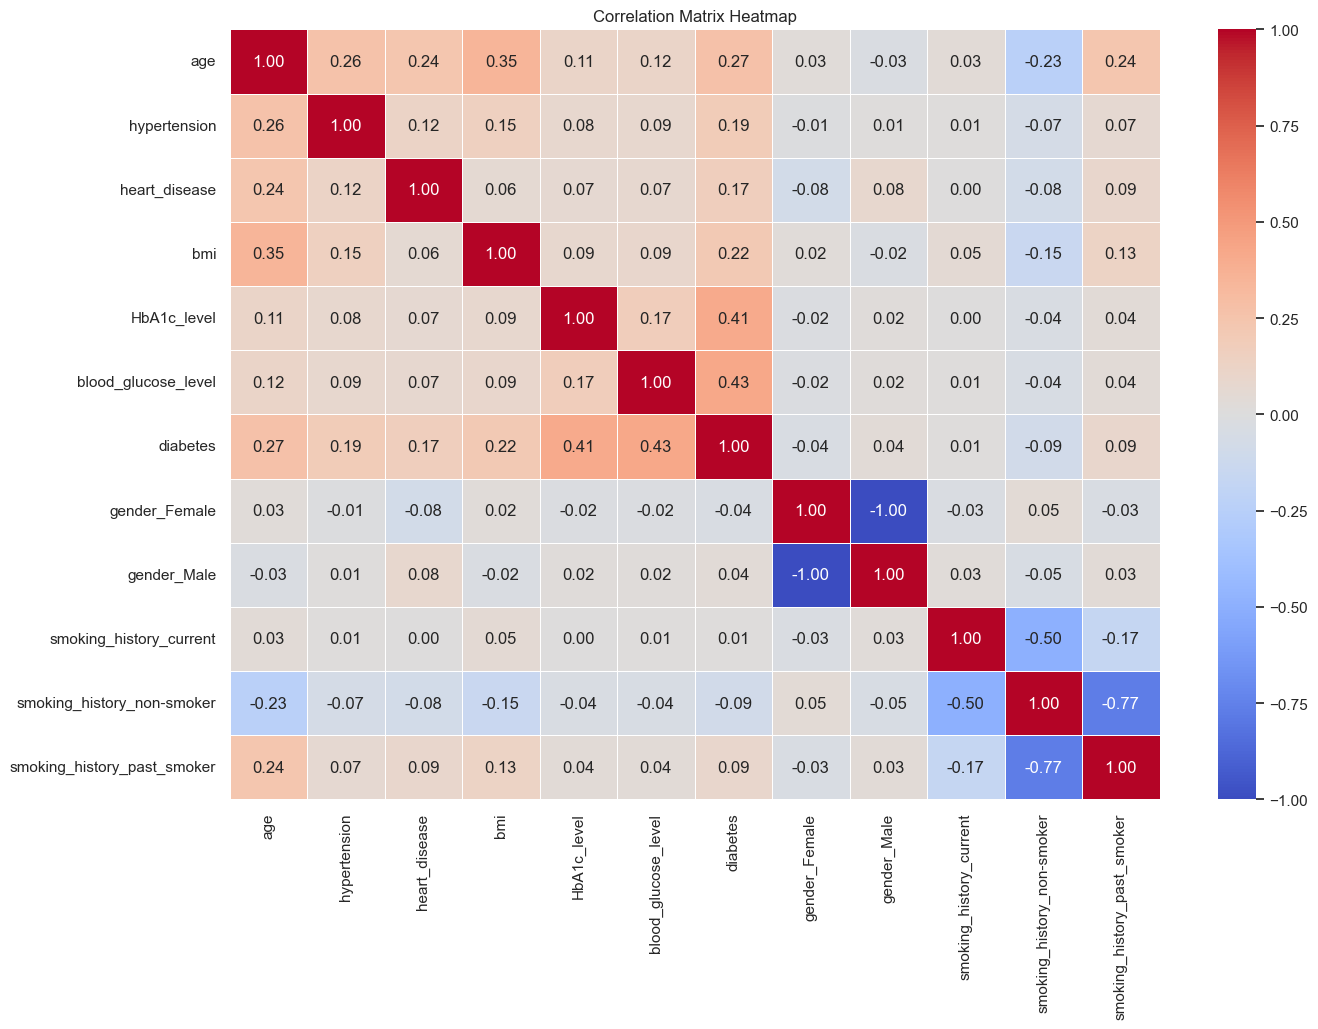

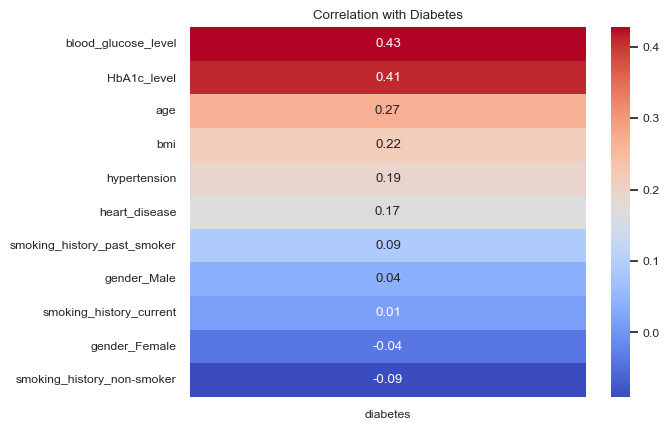

In [82]:
# Compute the correlation matrix
correlation_matrix = data.corr()
#Graph I.
plt.figure(figsize=(15, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', linewidths=0.5, fmt='.2f')
plt.title("Correlation Matrix Heatmap")
plt.show()


#Graph II
# Create a heatmap of the correlations with the target column
corr = data.corr()
target_corr = corr['diabetes'].drop('diabetes')

# Sort correlation values in descending order
target_corr_sorted = target_corr.sort_values(ascending=False)

sns.set(font_scale=0.8)
sns.set_style("white")
sns.set_palette("PuBuGn_d")
sns.heatmap(target_corr_sorted.to_frame(), cmap="coolwarm", annot=True, fmt='.2f')
plt.title('Correlation with Diabetes')
plt.show()

<b><span style='color:white'>3 |  PREDICTIVE ANALYSIS </span></b> </div>

<b><span style='color:white'> 1. Class Imbalance</span></b> </div>



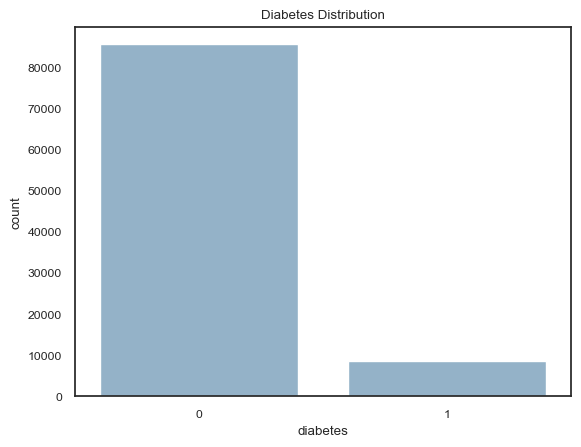

In [83]:
# Count plot for the 'diabetes' variable
sns.countplot(x='diabetes', data=df)
plt.title('Diabetes Distribution')
plt.show()

In [84]:
# Define resampling
over = SMOTE(sampling_strategy=0.1)
under = RandomUnderSampler(sampling_strategy=0.5)

<b><span style='color:white'> 2.Preprocessing : Scaler</span></b> </div>



In [85]:
# Define preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level','hypertension','heart_disease']),
        ('cat', OneHotEncoder(), ['gender','smoking_history'])
    ])

# Split data into features and target variable
X = df.drop('diabetes', axis=1)
y = df['diabetes']

In [86]:
# Create a pipeline that preprocesses the data, resamples data, and then trains a classifier
clf = imbPipeline(steps=[('preprocessor', preprocessor),
                      ('over', over),
                      ('under', under),
                      ('classifier', RandomForestClassifier())])

<b><span style='color:White'> 3. Model Building and Hyperparameter Tuning</span></b> </div>

In [87]:
# Define the hyperparameters and the values we want to test
param_grid = {
    'classifier__n_estimators': [50, 100, 200],
    'classifier__max_depth': [None, 10, 20],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4]
}

In [88]:
# Create Grid Search object
grid_search = GridSearchCV(clf, param_grid, cv=5)

# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train the model
grid_search.fit(X_train, y_train)

# Print the best parameters
print("Best Parameters: ", grid_search.best_params_)

Best Parameters:  {'classifier__max_depth': 10, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 200}


![](https://digitalpress.fra1.cdn.digitaloceanspaces.com/mhujhsj/2022/09/Internal-Nodes-crop-1.png)

<br>


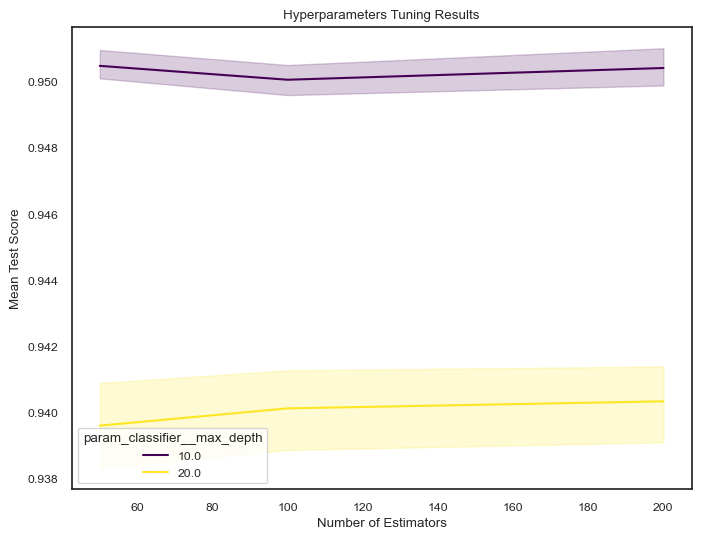

In [89]:
# Convert GridSearchCV results to a DataFrame and plot
results_df = pd.DataFrame(grid_search.cv_results_)
plt.figure(figsize=(8, 6))
sns.lineplot(data=results_df, x='param_classifier__n_estimators', y='mean_test_score', hue='param_classifier__max_depth', palette='viridis')
plt.title('Hyperparameters Tuning Results')
plt.xlabel('Number of Estimators')
plt.ylabel('Mean Test Score')
plt.show()

<b> 4. Confusion Matrix</span></b> </div>

Model Accuracy:  0.9523277467411546
              precision    recall  f1-score   support

           0       0.98      0.97      0.97     17108
           1       0.71      0.80      0.75      1687

    accuracy                           0.95     18795
   macro avg       0.84      0.89      0.86     18795
weighted avg       0.96      0.95      0.95     18795



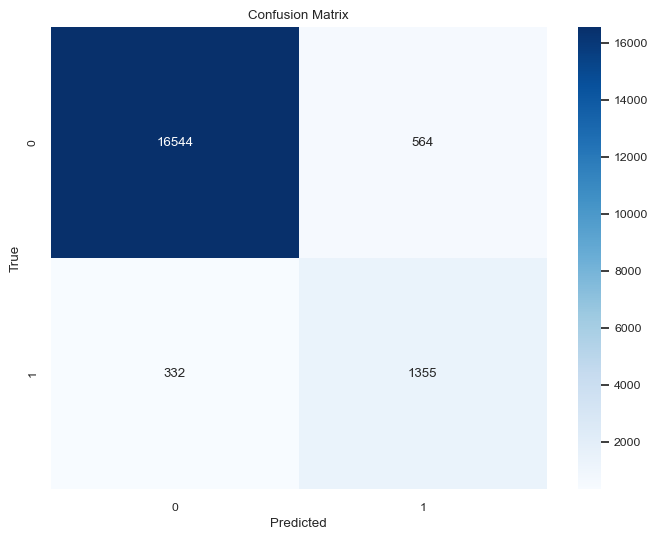

In [93]:
# Predict on the test set using the best model
y_pred = grid_search.predict(X_test)

# Evaluate the model
print("Model Accuracy: ", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

# Plot confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

<b> 4. Feature Importance</span></b> </div>

                        Feature  Importance
2                   HbA1c_level        0.44
3           blood_glucose_level        0.31
0                           age        0.13
1                           BMI        0.06
4                  hypertension        0.03
5                 heart_disease        0.02
10  smoking_history_past_smoker        0.00
9    smoking_history_non-smoker        0.00
7                   gender_Male        0.00
6                 gender_Female        0.00
8       smoking_history_current        0.00


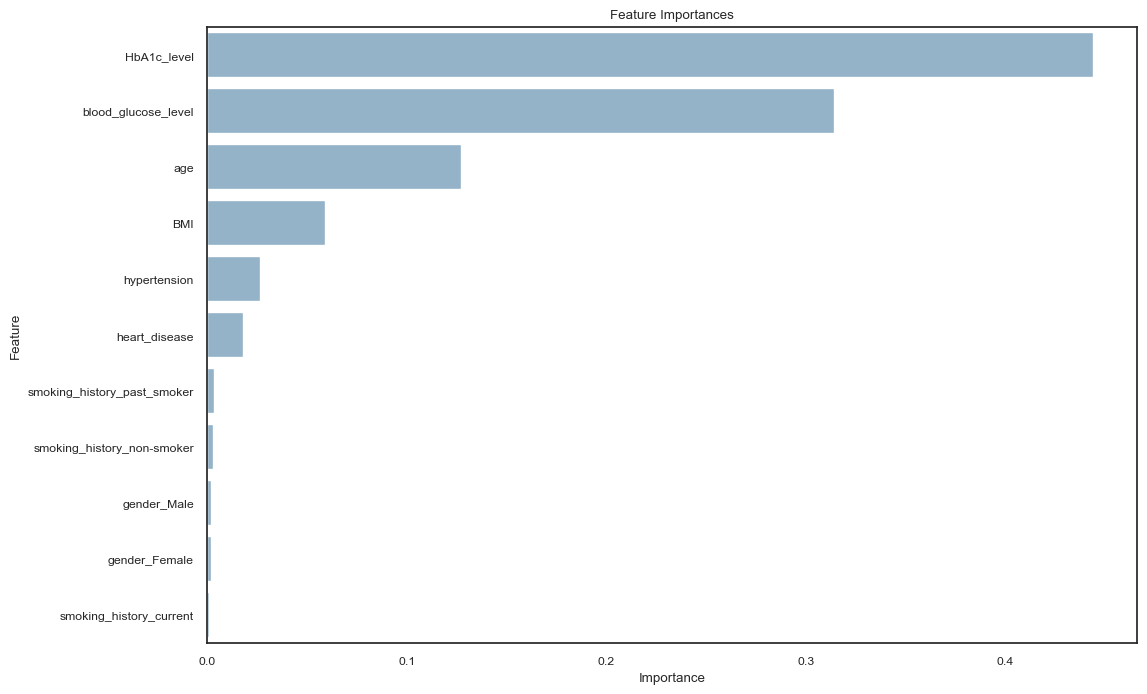

In [94]:
# After fitting the model, we input feature names
onehot_columns = list(grid_search.best_estimator_.named_steps['preprocessor'].named_transformers_['cat'].get_feature_names_out(['gender', 'smoking_history']))

# Then we add the numeric feature names
feature_names = ['age', 'BMI', 'HbA1c_level', 'blood_glucose_level', 'hypertension', 'heart_disease'] + onehot_columns

# And now let's get the feature importances
importances = grid_search.best_estimator_.named_steps['classifier'].feature_importances_

# Create a dataframe for feature importance
importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})

# Sort the dataframe by importance
importance_df = importance_df.sort_values('Importance', ascending=False)

# Print the feature importances
print(importance_df)

# Plot the feature importances
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=importance_df)
plt.title('Feature Importances')
plt.show()

In [95]:
import pickle

# After grid_search.fit(...):
best_pipeline = grid_search.best_estimator_

# Save the pipeline to disk using pickle
with open("diabetes_rf_pipeline.pkl", "wb") as f:
    pickle.dump(best_pipeline, f)